# TabM tuning and results

Run the planned TabM experiment and inspect its actual saved results. This notebook owns
TabM only. The command-line scripts and notebook use the same resumable experiment.

**Protocol:** 10 patient outer folds, 3 inner folds, blocks 2/3/4, width 128,
16 members, dropout 0.1, no numerical embeddings, AdamW learning rate 0.0003,
weight decay 0.0001, batches of 256 and **100 epochs per fit**. Choose mean observed
inner macro-F1, with simpler ties and at most one endpoint grid refinement.
Aâ€“D and four availability/duplicate controls are included. A full run requires
at least 800 fits and can take several days on a laptop GPU.

Select a Python kernel with the TabM requirements installed. `RUN_TRAINING` defaults to false,
so Run All inspects saved results. Set `TABM_RUN_TRAINING=1` before launching
Jupyter, or explicitly set `RUN_TRAINING=True`, to start/resume training.
The retained full run contains all requested outer folds; the completion checks below verify that coverage.

In [ ]:
from pathlib import Path
import os, sys, json, subprocess
import pandas as pd
from IPython.display import display, Markdown, Image

PROJECT = next(
    (candidate for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (candidate / 'requirements.txt').is_file()
     and (candidate / 'src' / 'afib').is_dir()
     and (candidate / 'models').is_dir()),
    None,
)
if PROJECT is None:
    raise FileNotFoundError('Run this notebook from the repository root or a directory inside it.')
if not (PROJECT / 'models/tabm/run_experiment.py').exists():
    raise RuntimeError('Open Jupyter from the repository root or a directory inside it.')
sys.path.insert(0, str(PROJECT))
OUTPUT = PROJECT / 'results/tabm'
RUN_TRAINING = os.environ.get('TABM_RUN_TRAINING', '0') == '1'
REFRESH_REPORTS = RUN_TRAINING or os.environ.get('TABM_REFRESH_REPORTS', '0') == '1'
print('Training enabled:', RUN_TRAINING)
print('Python:', sys.executable)
print('Output:', OUTPUT)

## Run each initial parameter setting

Each script fits one block setting across all 8 variants and all 30 inner splits.
Existing matching results are reused. An incompatible code, data or runtime signature
raises an error instead of mixing experiments. Do not run multiple trainers against
the same output folder. Outer patients never select a parameter or threshold.

In [2]:
def run_script(filename, *arguments):
    command = [sys.executable, str(PROJECT / 'models/tabm' / filename),
               '--output', str(OUTPUT), *arguments]
    if not RUN_TRAINING:
        print('Inspection mode; skipped:', filename, *arguments)
        return
    log_dir = OUTPUT / 'logs'
    log_dir.mkdir(parents=True, exist_ok=True)
    log_path = log_dir / (Path(filename).stem + '_notebook.log')
    print('Running', filename, '; full log:', log_path, flush=True)
    with log_path.open('a', encoding='utf-8') as log:
        process = subprocess.Popen(command, cwd=PROJECT, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True, bufsize=1)
        try:
            for line in process.stdout:
                log.write(line)
                log.flush()
                if any(word in line.lower() for word in ['complete', 'resume', 'error', 'traceback']):
                    print(line.rstrip(), flush=True)
            if process.wait():
                raise RuntimeError(f'{filename} failed; inspect {log_path}')
        except BaseException:
            process.terminate()
            process.wait()
            raise

In [ ]:
run_script('run_blocks_2.py')

In [ ]:
run_script('run_blocks_3.py')

In [ ]:
run_script('run_blocks_4.py')

## Select, refit and evaluate

This step reuses the three initial candidates, evaluates block 1 or 5 only if
an initial endpoint wins, and freezes the chosen setting. It refits on outer
training patients and tests all 31 scenario/repeat conditions. Threshold 0.5
is primary; the exploratory 0.90-sensitivity threshold comes from selected
inner out-of-fold predictions and remains frozen for every outer stress.

In [ ]:
run_script('run_experiment.py', '--phase', 'run')

## Inspect completion and optionally refresh reports

Predictions, histories and audits live in `results/tabm/output_data/`;
aggregate tables also live there; figures and the written report live in `results/tabm/reports/`.
Binary resume checkpoints stay locally in `results/tabm/checkpoints/`.
Inspection leaves saved reports unchanged. Set `TABM_REFRESH_REPORTS=1` to rebuild
reports explicitly. Reports label partial results explicitly. Repeats are averaged within each
outer fold before calculating fold means and sample SD.

In [ ]:
from models.tabm.reporting import generate_reports
if REFRESH_REPORTS and (OUTPUT / 'run_config.json').exists():
    generate_reports(OUTPUT)
elif not (OUTPUT / 'run_config.json').exists():
    print('No full experiment has started yet.')
for name in ['status.json', 'reports/completion.json', 'completion.json']:
    path = OUTPUT / name
    if path.exists():
        display(Markdown(f'**{name}**'))
        display(json.loads(path.read_text(encoding='utf-8')))

In [8]:
# Show published result tables without assuming all outer folds exist.
for name in ['summary.csv', 'selected_hyperparameters.csv', 'tuning_progress.csv',
             'paired_method_differences.csv', 'paired_stress_drops.csv',
             'patient_weighted_metrics_summary.csv', 'quality_subgroups_summary.csv']:
    paths = [OUTPUT / 'reports' / name, OUTPUT / 'output_data' / name]
    path = next((p for p in paths if p.exists()), None)
    if path:
        display(Markdown(f'**{name}**'))
        try:
            display(pd.read_csv(path).head(40))
        except pd.errors.EmptyDataError:
            print('No completed results for this table yet.')

**summary.csv**

,variant,scenario,threshold_policy,metric,mean,sd,n_folds,n_defined
0,A,combined_3lead_noise0.10,fixed_0.50,macro_f1,0.898254,0.012668,10,10
1,A,combined_3lead_noise0.10,fixed_0.50,sensitivity,0.734818,0.033895,10,10
2,A,combined_3lead_noise0.10,fixed_0.50,specificity,0.994016,0.002010,10,10
3,A,combined_3lead_noise0.10,fixed_0.50,precision,0.902452,0.030927,10,10
4,A,combined_3lead_noise0.10,fixed_0.50,npv,0.980499,0.002368,10,10
5,A,combined_3lead_noise0.10,fixed_0.50,balanced_accuracy,0.864417,0.016800,10,10
6,A,combined_3lead_noise0.10,fixed_0.50,accuracy,0.976027,0.002578,10,10
7,A,combined_3lead_noise0.10,fixed_0.50,auroc,0.989053,0.004284,10,10
8,A,combined_3lead_noise0.10,fixed_0.50,average_precision,0.899441,0.026136,10,10
9,A,combined_3lead_noise0.10,fixed_0.50,brier,0.017893,0.001897,10,10


**selected_hyperparameters.csv**

,model,variant,feature_set,training_arm,outer_fold,n_blocks,initial_grid,final_grid,refined,selected_middle,inner_mean_macro_f1,secondary_threshold,seconds
0,tabm,A,original,observed,0,3,"[2, 3, 4]","[2, 3, 4]",False,True,0.934411,"{'threshold': 0.54462730884552, 'status': 'sel...",354.492036
1,tabm,B,enhanced,observed,0,1,"[2, 3, 4]","[1, 2, 3]",True,False,0.936097,"{'threshold': 0.5991793870925903, 'status': 's...",463.870205
2,tabm,C,original,augmented,0,4,"[2, 3, 4]","[3, 4, 5]",True,True,0.933965,"{'threshold': 0.56955885887146, 'status': 'sel...",357.593457
3,tabm,D,enhanced,augmented,0,4,"[2, 3, 4]","[3, 4, 5]",True,True,0.937539,"{'threshold': 0.5877039432525635, 'status': 's...",877.971756
4,tabm,availability_observed,enhanced,observed,0,2,"[2, 3, 4]","[1, 2, 3]",True,True,0.932494,"{'threshold': 0.5639926195144653, 'status': 's...",433.327471
5,tabm,availability_augmented,enhanced,augmented,0,2,"[2, 3, 4]","[1, 2, 3]",True,True,0.932845,"{'threshold': 0.4790146946907043, 'status': 's...",765.780807
6,tabm,duplicate_original,original,observed,0,3,"[2, 3, 4]","[2, 3, 4]",False,True,0.933431,"{'threshold': 0.5427462458610535, 'status': 's...",491.877659
7,tabm,duplicate_enhanced,enhanced,observed,0,2,"[2, 3, 4]","[1, 2, 3]",True,True,0.938280,"{'threshold': 0.5421713590621948, 'status': 's...",685.610051
8,tabm,A,original,observed,1,3,"[2, 3, 4]","[2, 3, 4]",False,True,0.931980,"{'threshold': 0.5201349854469299, 'status': 's...",261.865513
9,tabm,B,enhanced,observed,1,2,"[2, 3, 4]","[1, 2, 3]",True,True,0.933913,"{'threshold': 0.5664162635803223, 'status': 's...",421.316269


**tuning_progress.csv**

...

,variant,threshold_policy,scenario,metric,n_folds,n_defined,mean_deterioration,sd_deterioration
0,A,fixed_0.50,combined_3lead_noise0.10,macro_f1,10,10,0.033871,0.009207
1,A,fixed_0.50,combined_3lead_noise0.10,sensitivity,10,10,0.175944,0.016058
2,A,fixed_0.50,combined_3lead_noise0.10,specificity,10,10,-0.006958,0.002000
3,A,fixed_0.50,combined_3lead_noise0.10,precision,10,10,-0.060821,0.013912
4,A,fixed_0.50,combined_3lead_noise0.10,npv,10,10,0.012802,0.001033
5,A,fixed_0.50,combined_3lead_noise0.10,balanced_accuracy,10,10,0.084493,0.008202
6,A,fixed_0.50,combined_3lead_noise0.10,accuracy,10,10,0.005729,0.002302
7,A,fixed_0.50,combined_3lead_noise0.10,auroc,10,10,0.002941,0.002132
8,A,fixed_0.50,combined_3lead_noise0.10,average_precision,10,10,0.023120,0.010664
9,A,fixed_0.50,combined_3lead_noise0.10,brier,10,10,0.003655,0.001650


**patient_weighted_metrics_summary.csv**

,variant,scenario,threshold_policy,metric,mean,sd,n_folds,n_defined
0,A,combined_3lead_noise0.10,fixed_0.50,macro_f1,0.897797,0.014906,10,10
1,A,combined_3lead_noise0.10,fixed_0.50,sensitivity,0.730639,0.039789,10,10
2,A,combined_3lead_noise0.10,fixed_0.50,specificity,0.994851,0.001421,10,10
3,A,combined_3lead_noise0.10,fixed_0.50,balanced_accuracy,0.862745,0.019895,10,10
4,A,combined_3lead_noise0.10,fixed_0.50,accuracy,0.978709,0.002602,10,10
5,A,combined_3lead_noise0.10,fixed_0.50,brier,0.015786,0.001997,10,10
6,A,combined_3lead_noise0.10,inner_sensitivity_0.90,macro_f1,0.894523,0.021003,10,10
7,A,combined_3lead_noise0.10,inner_sensitivity_0.90,sensitivity,0.720587,0.058408,10,10
8,A,combined_3lead_noise0.10,inner_sensitivity_0.90,specificity,0.995002,0.001264,10,10
9,A,combined_3lead_noise0.10,inner_sensitivity_0.90,balanced_accuracy,0.857795,0.029106,10,10


**quality_subgroups_summary.csv**

,variant,scenario,threshold_policy,subgroup,metric,mean,sd,n_folds,n_defined
0,A,combined_3lead_noise0.10,fixed_0.50,no_recorded_quality_flag,macro_f1,0.897263,0.012302,10,10
1,A,combined_3lead_noise0.10,fixed_0.50,no_recorded_quality_flag,sensitivity,0.735461,0.035319,10,10
2,A,combined_3lead_noise0.10,fixed_0.50,no_recorded_quality_flag,specificity,0.994025,0.001922,10,10
3,A,combined_3lead_noise0.10,fixed_0.50,no_recorded_quality_flag,precision,0.895151,0.032527,10,10
4,A,combined_3lead_noise0.10,fixed_0.50,no_recorded_quality_flag,npv,0.981962,0.002731,10,10
5,A,combined_3lead_noise0.10,fixed_0.50,no_recorded_quality_flag,balanced_accuracy,0.864743,0.017393,10,10
6,A,combined_3lead_noise0.10,fixed_0.50,no_recorded_quality_flag,accuracy,0.977322,0.002481,10,10
7,A,combined_3lead_noise0.10,fixed_0.50,no_recorded_quality_flag,auroc,0.990432,0.003547,10,10
8,A,combined_3lead_noise0.10,fixed_0.50,no_recorded_quality_flag,average_precision,0.896143,0.032157,10,10
9,A,combined_3lead_noise0.10,fixed_0.50,no_recorded_quality_flag,brier,0.016682,0.001852,10,10


**calibration**

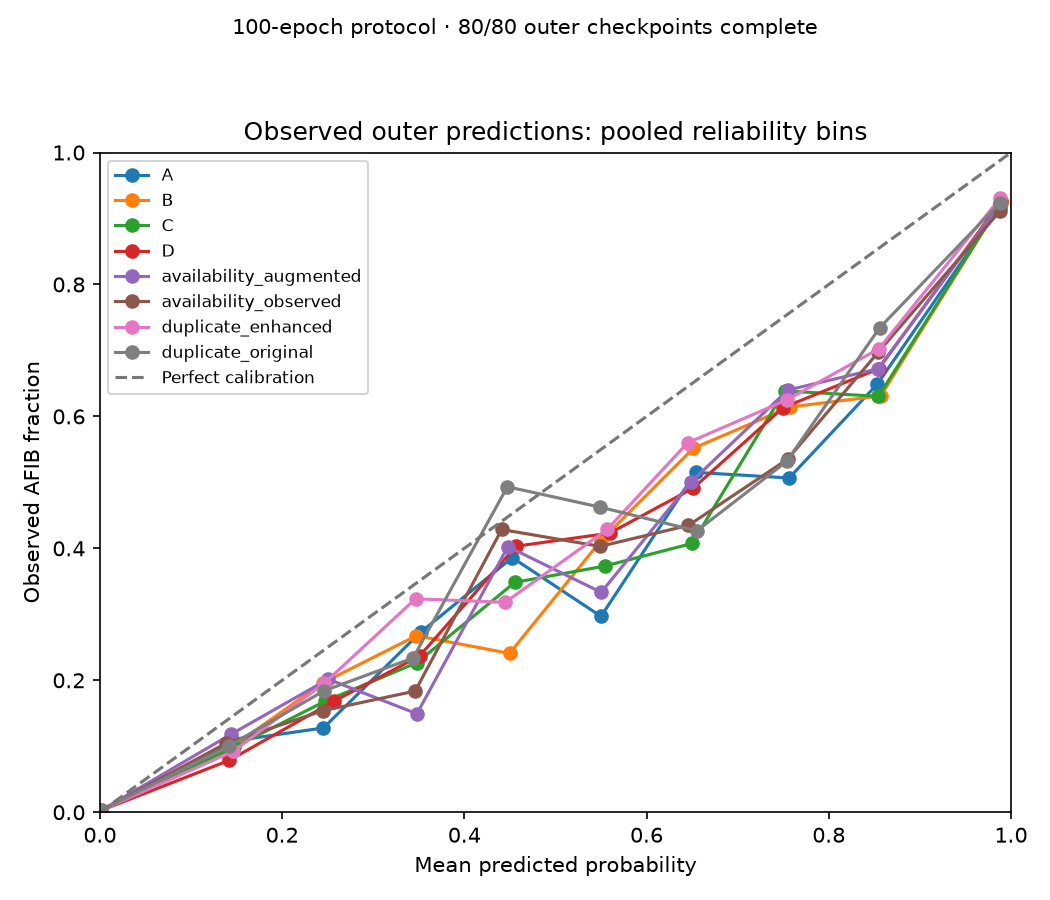

**progress**

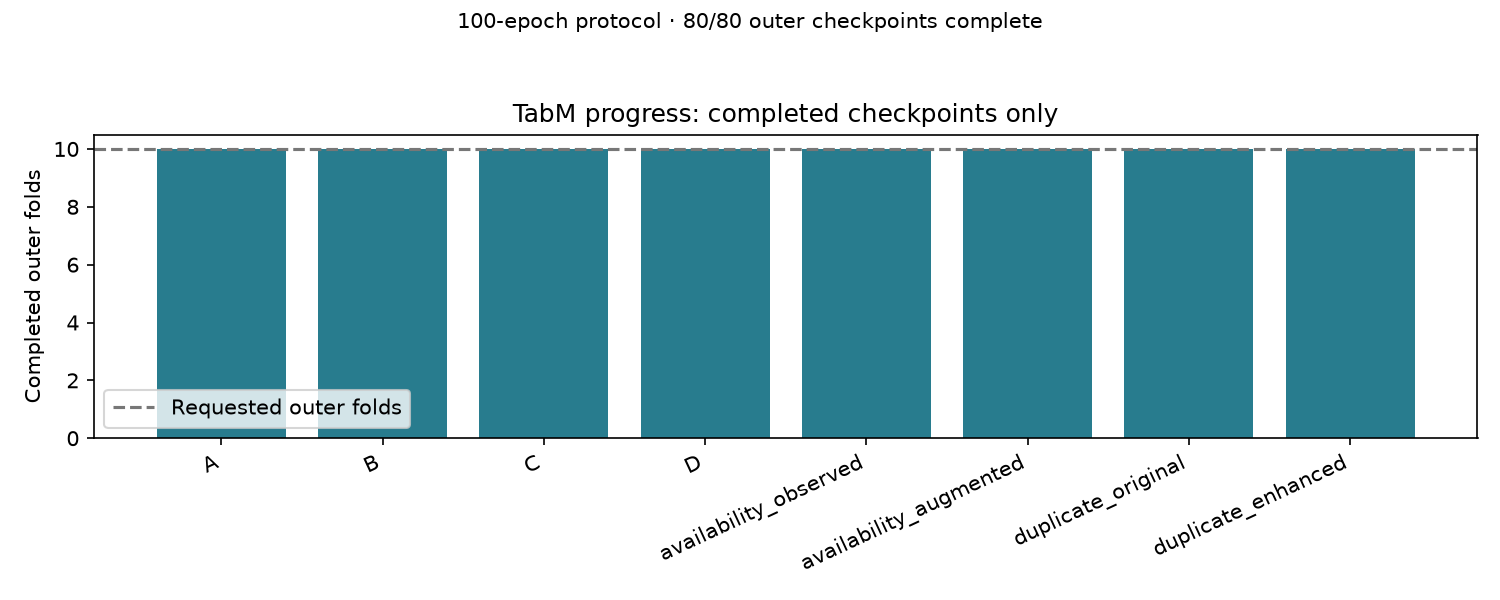

**robustness brier**

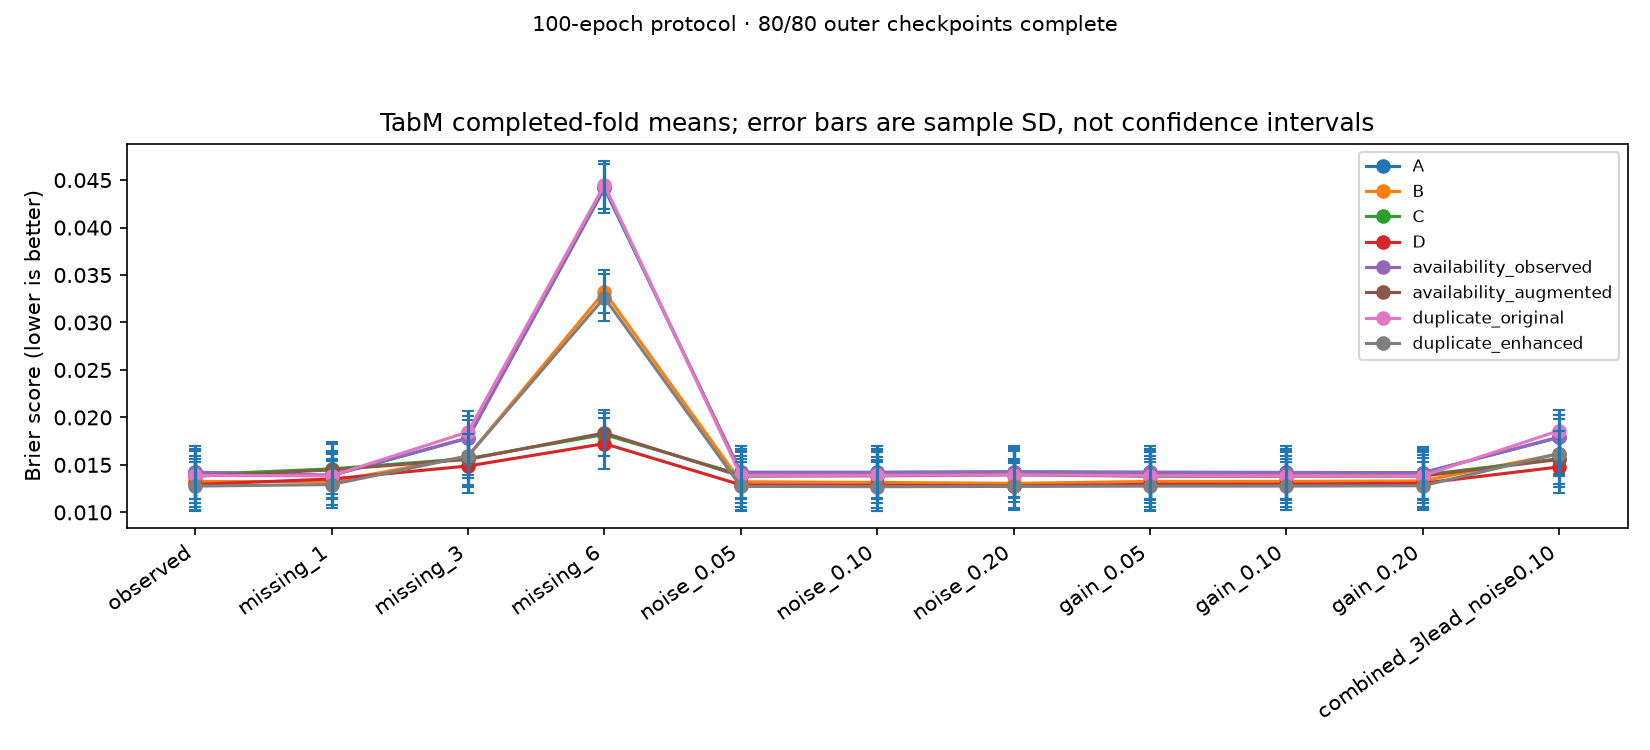

**robustness macro f1**

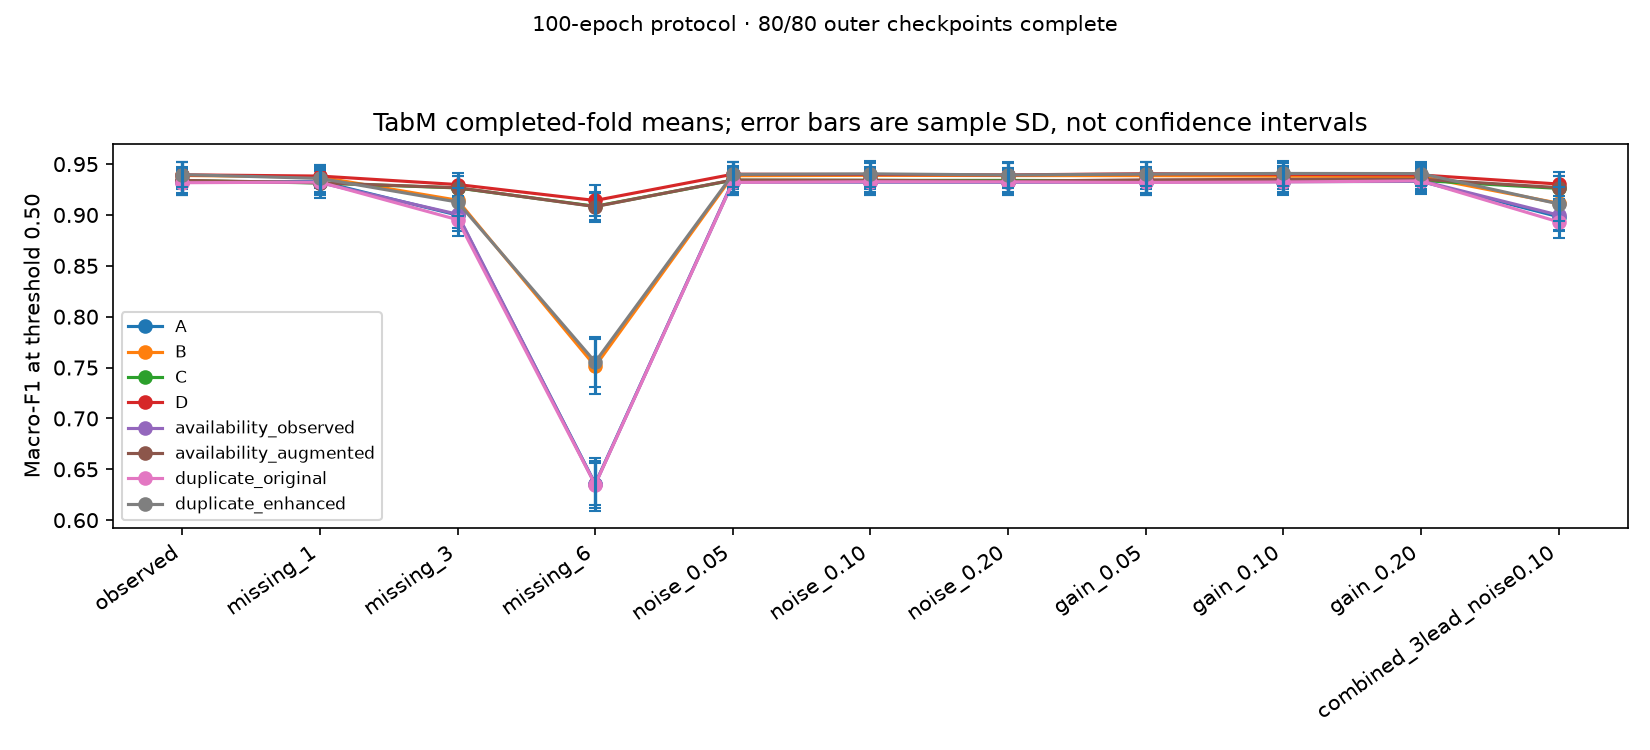

**robustness sensitivity**

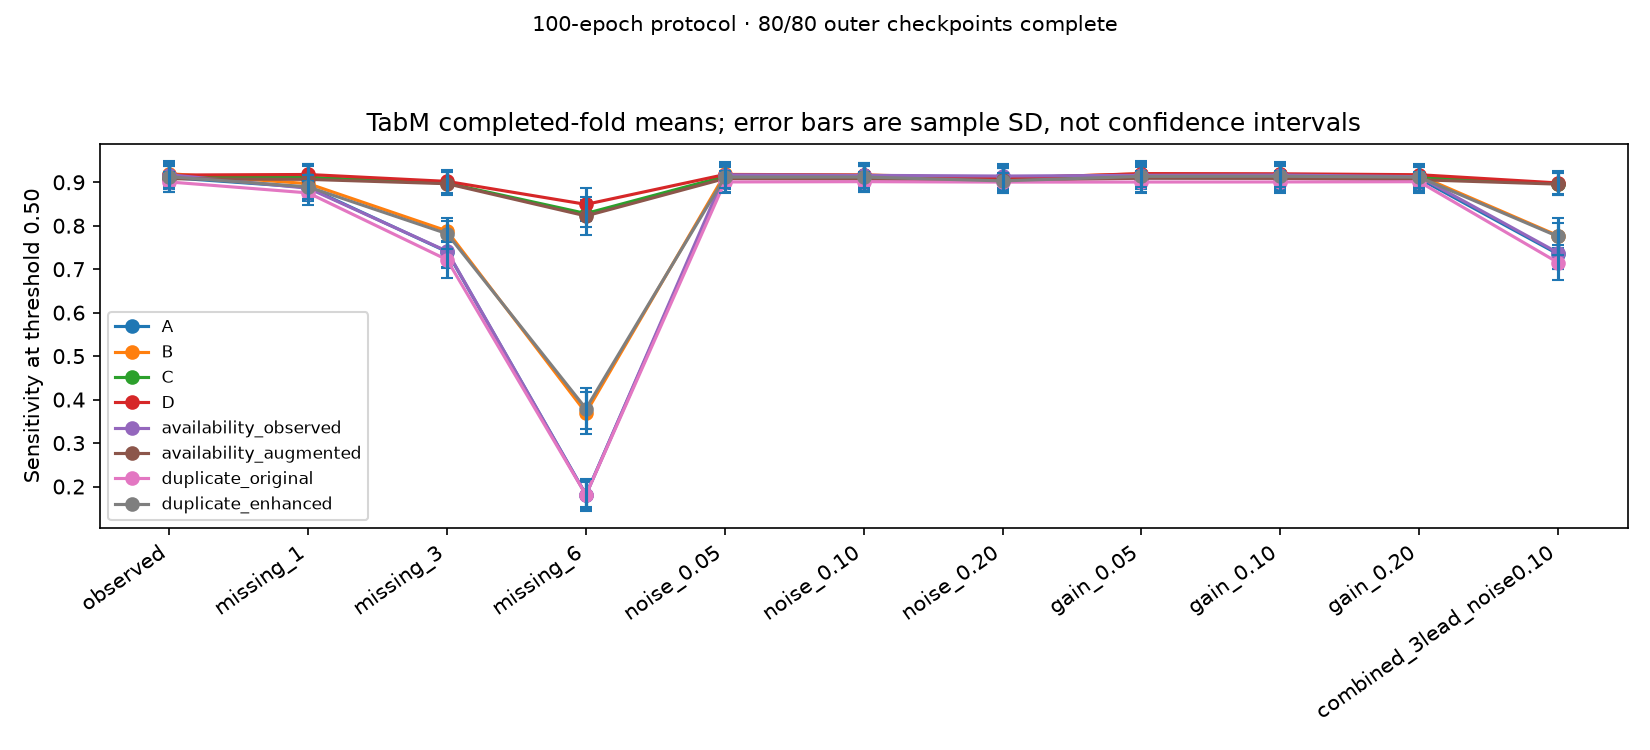

**training loss**

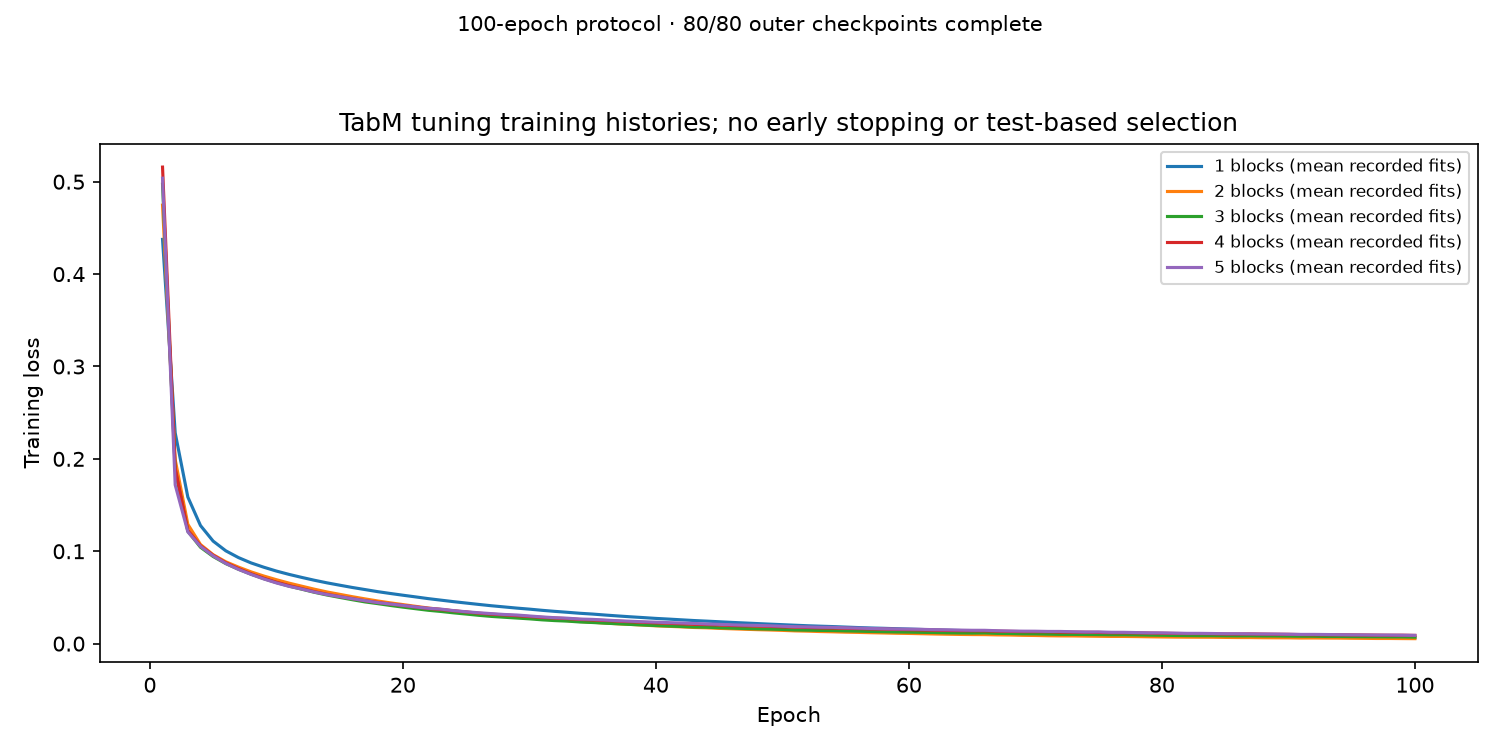

# TabM experiment report â€” COMPLETE TABM PLAN

Generated 2026-10-13T04:30:34.388815+00:00. Requested scope: **complete**.
**80/80 outer-fold/variant checkpoints** and **10/10 complete outer folds** are available.
There are **891 completed inner fits**, **80 outer refits**, and **297 fully evaluated tuning candidates**.
The initial grid requires 720 inner fits; endpoint refinement can require more.
Completing a reduced run does not establish completion of the project plan.

Only completed outer checkpoints enter performance summaries. Partial tuning scores are validation scores, not final model results. A single completed outer fold has undefined sample SD. Empty figures mean the relevant results are not available; no values have been estimated or fabricated.

## Settings and runtime

Requested variants: A, B, C, D, availability_observed, availability_augmented, duplicate_original, duplicate_enhanced. Outer folds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]; inner folds: 3.
Initial block grid: [2, 3, 4]; one-step endpoint refinement: True.
Every fit requests 100 epochs and batch size 256; stress repeats: 3 (31 conditions per outer checkpoint).
Device: cuda; seed: 20261008.
Sum of completed-fold wall times: 47064.6 seconds (not total elapsed experiment time).

```json
{
  "architecture": {
    "width": 128,
    "members": 16,
    "dropout": 0.1,
    "numerical_embeddings": false
  },
  "optimizer": {
    "name": "AdamW",
    "learning_rate": 0.0003,
    "weight_decay": 0.0001
  },
  "versions": {
    "python": "3.12.10",
    "numpy": "2.5.1",
    "pandas": "3.0.6",
    "torch": "2.7.1+cu128",
    "tabm": "0.0.3"
  }
}
```

## Observed performance at the fixed 0.50 threshold

| variant | metric | mean | sd | n_folds | n_defined |
| --- | --- | --- | --- | --- | --- |
| A | macro_f1 | 0.9321 | 0.0126 | 10 | 10 |
| A | sensitivity | 0.9108 | 0.0258 | 10 | 10 |
| A | specificity | 0.9871 | 0.0039 | 10 | 10 |
| A | brier | 0.0142 | 0.0028 | 10 | 10 |
| B | macro_f1 | 0.9389 | 0.0137 | 10 | 10 |
| B | sensitivity | 0.9199 | 0.0291 | 10 | 10 |
| B | specificity | 0.9884 | 0.0028 | 10 | 10 |
| B | brier | 0.0133 | 0.0027 | 10 | 10 |
| C | macro_f1 | 0.9338 | 0.0121 | 10 | 10 |
| C | sensitivity | 0.9134 | 0.0281 | 10 | 10 |
| C | specificity | 0.9874 | 0.0035 | 10 | 10 |
| C | brier | 0.0140 | 0.0026 | 10 | 10 |
| D | macro_f1 | 0.9395 | 0.0122 | 10 | 10 |
| D | sensitivity | 0.9166 | 0.0261 | 10 | 10 |
| D | specificity | 0.9889 | 0.0030 | 10 | 10 |
| D | brier | 0.0129 | 0.0027 | 10 | 10 |
| availability_augmented | macro_f1 | 0.9340 | 0.0132 | 10 | 10 |
| availability_augmented | sensitivity | 0.9081 | 0.0312 | 10 | 10 |
| availability_augmented | specificity | 0.9879 | 0.0035 | 10 | 10 |
| availability_augmented | brier | 0.0138 | 0.0029 | 10 | 10 |
| availability_observed | macro_f1 | 0.9332 | 0.0132 | 10 | 10 |
| availability_observed | sensitivity | 0.9174 | 0.0299 | 10 | 10 |
| availability_observed | specificity | 0.9868 | 0.0034 | 10 | 10 |
| availability_observed | brier | 0.0142 | 0.0028 | 10 | 10 |
| duplicate_enhanced | macro_f1 | 0.9397 | 0.0120 | 10 | 10 |
| duplicate_enhanced | sensitivity | 0.9127 | 0.0252 | 10 | 10 |
| duplicate_enhanced | specificity | 0.9894 | 0.0025 | 10 | 10 |
| duplicate_enhanced | brier | 0.0128 | 0.0026 | 10 | 10 |
| duplicate_original | macro_f1 | 0.9317 | 0.0117 | 10 | 10 |
| duplicate_original | sensitivity | 0.9007 | 0.0239 | 10 | 10 |
| duplicate_original | specificity | 0.9879 | 0.0030 | 10 | 10 |
| duplicate_original | brier | 0.0139 | 0.0025 | 10 | 10 |

## Protocol and interpretation

All preprocessing, imputation, scaling and augmentation are fitted using training patients only. Block count is selected using mean inner-fold macro-F1; ties favor fewer blocks. The secondary threshold is selected from inner out-of-fold predictions to target sensitivity 0.90, then frozen for every outer condition. It is an exploratory threshold, not a clinical acceptance criterion.

Stress repeats are averaged within each outer fold before calculating the outer-fold mean and sample SD. Undefined metrics propagate through both aggregation stages. Error bars are descriptive sample SD, not confidence intervals; outer folds share training data. Positive paired stress deterioration means performance becomes worse (stress minus observed for Brier; observed minus stress otherwise). Method differences are left minus right on the intersection of completed folds, for both threshold policies.

The reports include Bâ€“A, Dâ€“C, Câ€“A and Dâ€“B plus B/availability-observed, D/availability-augmented and both duplicate controls when paired results exist. Patient-weighted metrics give each patient total weight one. Quality groups use recorded source annotations; an absent flag does not prove a clean signal. The simulated tabular corruptions are not calibrated ECG waveform artefacts.

Majority baseline: computed from training labels only; current data manifest verified. It can be computed before any model finishes and is not evidence of completed model training.

## Figures

![Outer-fold progress](progress.png)

![Macro-F1 robustness](robustness_macro_f1.png)

![Sensitivity robustness](robustness_sensitivity.png)

![Brier-score robustness](robustness_brier.png)

![Calibration](calibration.png)

![Training](training_loss.png)

Calibration pools observed test records into ten probability bins across completed folds. Training curves average recorded histories at each epoch; they do not select the final model.

## Saved evidence

The sibling `output_data/` directory contains raw fold tables, predictions, tuning candidates, `summary.csv`, `fold_mean_metrics.csv`, paired contrasts, patient-weighted and quality-group summaries, majority baseline, and tuning progress. Checkpoint models are stored separately in `checkpoints/`. `completion.json` records missing checkpoints and precise coverage. Source hashes, processed-data manifest, and runtime versions are preserved in `../run_config.json`.

These report-generation coverage checks do not replace the independent `check_results.py` audit, which recalculates saved prediction metrics and checks patient separation, complete scenario coverage and settings. No results from other classifiers are required for this TabM report.


In [9]:
for path in sorted((OUTPUT / 'reports').glob('*.png')):
    display(Markdown(f'**{path.stem.replace("_", " ")}**'))
    display(Image(filename=str(path)))
for name in ['report.md', 'README.md']:
    path = OUTPUT / 'reports' / name
    if path.exists():
        display(Markdown(path.read_text(encoding='utf-8')))
        break

In [ ]:
# Validate the complete submitted run; do not accept missing outer folds.
command = [sys.executable, str(PROJECT / 'models/tabm/check_results.py'),
           '--output', str(OUTPUT)]
if (OUTPUT / 'run_config.json').exists():
    checked = subprocess.run(command, cwd=PROJECT, text=True, capture_output=True)
    print(checked.stdout)
    if checked.returncode:
        print(checked.stderr)
        raise RuntimeError('Result validation failed.')

## Interpretation and sources

Compare Bâˆ’A and Dâˆ’C for added feature values, Câˆ’A and Dâˆ’B for augmentation,
and the availability/duplicate controls before attributing an improvement.
Error bars describe variation across dependent outer folds; they are not
clinical confidence intervals. Missing extracted measurements do not simulate
physical electrode removal. No clinical benefit follows from this experiment alone.

Protocol: `docs/Project_Plan.docx` (8 October 2026).
[Official TabM implementation](https://github.com/yandex-research/tabm),
[TabM paper](https://arxiv.org/abs/2410.24210),
[PTB-XL+ 1.0.1](https://physionet.org/content/ptb-xl-plus/1.0.1/) and
[PTB-XL 1.0.3](https://physionet.org/content/ptb-xl/1.0.3/) (CC BY 4.0).